# Question 4.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

W = np.array([
[0., 5., 5., 5., 0., 0., 0., 0.],
[5., 0., 5., 5., 1., 0., 0., 0.],
[5., 5., 0., 5., 0., 1., 0., 0.],
[5., 5., 5., 0., 0., 0., 1., 0.],
[0., 1., 0., 0., 0., 5., 5., 5.],
[0., 0., 1., 0., 5., 0., 5., 5.],
[0., 0., 0., 1., 5., 5., 0., 5.],
[0., 0., 0., 0., 5., 5., 5., 0.]
])

## (a) Degree matrix D and unnormalized Laplacian L = D − W

In [9]:
d = W.sum(axis=1)          # degree of each node = row sums
D = np.diag(d)             # degree matrix
L = D - W                  # unnormalized Laplacian
print("degrees:", d)
print("D =\n", D)
print("L =\n", L)

degrees: [15. 16. 16. 16. 16. 16. 16. 15.]
D =
 [[15.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. 16.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. 16.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. 16.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. 16.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. 16.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. 16.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. 15.]]
L =
 [[15. -5. -5. -5.  0.  0.  0.  0.]
 [-5. 16. -5. -5. -1.  0.  0.  0.]
 [-5. -5. 16. -5.  0. -1.  0.  0.]
 [-5. -5. -5. 16.  0.  0. -1.  0.]
 [ 0. -1.  0.  0. 16. -5. -5. -5.]
 [ 0.  0. -1.  0. -5. 16. -5. -5.]
 [ 0.  0.  0. -1. -5. -5. 16. -5.]
 [ 0.  0.  0.  0. -5. -5. -5. 15.]]


## (b) Normalized Laplacian and its eigenvalues

Delta:
[[ 1.    -0.323 -0.323 -0.323  0.     0.     0.     0.   ]
 [-0.323  1.    -0.312 -0.312 -0.062  0.     0.     0.   ]
 [-0.323 -0.312  1.    -0.312  0.    -0.062  0.     0.   ]
 [-0.323 -0.312 -0.312  1.     0.     0.    -0.062  0.   ]
 [ 0.    -0.062  0.     0.     1.    -0.312 -0.312 -0.323]
 [ 0.     0.    -0.062  0.    -0.312  1.    -0.312 -0.323]
 [ 0.     0.     0.    -0.062 -0.312 -0.312  1.    -0.323]
 [ 0.     0.     0.     0.    -0.323 -0.323 -0.323  1.   ]]
eigenvalues of Delta: [0.     0.093  1.25   1.25   1.3125 1.3445 1.375  1.375 ]


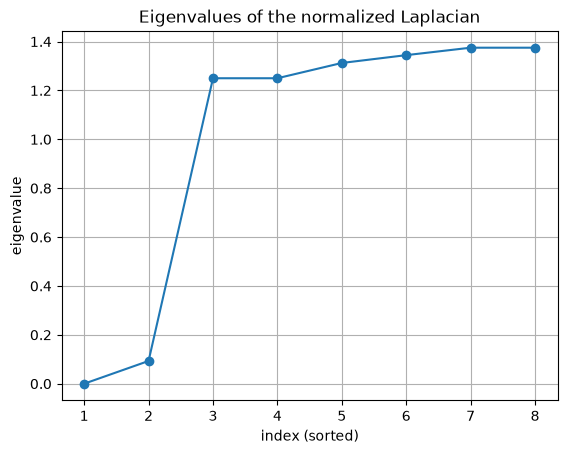

In [10]:
D_inv_sqrt = np.diag(1 / np.sqrt(d))
Delta = D_inv_sqrt @ L @ D_inv_sqrt

with np.printoptions(precision=3, suppress=True):
    print("Delta:")
    print(Delta)

eigvals = np.linalg.eigvalsh(Delta)   
print("eigenvalues of Delta:", np.round(eigvals, 4))

plt.plot(range(1, len(eigvals) + 1), eigvals, 'o-')
plt.xlabel("index (sorted)")
plt.ylabel("eigenvalue")
plt.title("Eigenvalues of the normalized Laplacian")
plt.grid(True)
plt.show()

The eigenvalues are 0, 0.093, 1.25, 1.25, 1.3125, 1.3445, 1.375 and 1.375, all between 0 and 2. The smallest is exactly 0, as it is for every graph Laplacian.

## (c) Number of natural clusters

The graph suggests **2 natural clusters**. Two eigenvalues are close to 0 (0 and 0.093), and then there is a big jump to the third one (1.25). The number of eigenvalues near 0 before this gap gives the number of clusters. 

## (d) Fiedler vector and 2-way clustering

In [11]:
eigvals, eigvecs = np.linalg.eigh(Delta)   # ascending eigenvalues
fiedler_value = eigvals[1]
g2 = eigvecs[:, 1]                         # Fiedler vector: eigenvector of 2nd-smallest eigenvalue

print("Fiedler value lambda_2 =", round(fiedler_value, 4))
print("Fiedler vector g2      =", np.round(g2, 4))

names = np.array([f"n{i}" for i in range(1, 9)])
A = names[g2 > 0]
A_bar = names[g2 <= 0]
print("Cluster A     (g2 > 0): ", A.tolist())
print("Cluster A_bar (g2 <= 0):", A_bar.tolist())

Fiedler value lambda_2 = 0.093
Fiedler vector g2      = [-0.371  -0.3475 -0.3475 -0.3475  0.3475  0.3475  0.3475  0.371 ]
Cluster A     (g2 > 0):  ['n5', 'n6', 'n7', 'n8']
Cluster A_bar (g2 <= 0): ['n1', 'n2', 'n3', 'n4']


## (e) Permuting rows and columns of W

**No.** Permuting rows and columns by the same permutation only relabels the vertices: $W' = PWP^\top$, so $D' = PDP^\top$ and $\Delta' = P\Delta P^\top$. This is a similarity transform, so $\Delta'$ has exactly the same eigenvalues and its eigenvectors are the old ones with entries reordered